01_data_preprocessing

In [1]:
from google.colab import drive
import os, json, torch
drive.mount('/content/drive')

USER = 'primaazahra'
REPO = 'wifi-csi-crossdomain-dann'
ROOT = '/content/drive/MyDrive/Project_UTS_BPV/BVP'
OUT = '/content/drive/MyDrive/Project_UTS_BPV/results'

os.makedirs(OUT, exist_ok=True)
!rm -rf /content/repo && git clone https://github.com/{USER}/{REPO}.git /content/repo
%cd /content/repo
!pip install -q -r requirements.txt
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Setup selesai! Menggunakan device:", device)

Mounted at /content/drive
Cloning into '/content/repo'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 17 (delta 1), reused 12 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 7.40 KiB | 7.40 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/repo
Setup selesai! Menggunakan device: cpu


In [2]:
!python prepare_split.py --root "{ROOT}"

Total .mat: 43658 | nama file terparse: 43658

user x gesture
 gesture    1     2     3     4     5     6    7    8    9    10
user                                                           
1        1425  1425  1425  1425  1425  1417  375  375  375  250
2        1875  1750  1749  1750  1625  1499  250  250  250  250
3        1249  1250  1250  1125  1125  1125    0    0    0    0
4         125   125   125   125   125   125    0    0    0    0
5         250   250   250   250   250   250  125  125  125    0
6         250   250   249   250   250   250    0    0    0    0
7         125   124   125   125   125   125    0    0    0    0
8         124   125   124   125   125   125    0    0    0    0
9         124   125   125   125   125   125    0    0    0    0
10        125   125   125   125   125   125  125  125  125    0
11        125   125   125   125   125   125  125  125  125    0
12        125   125   125   125   125   125  125  125  125    0
13        125   125   125   125   125   1

Config Dataset: {'domain': 'user', 'source': [2, 3, 1], 'target': [5, 6], 'GESTURES': [1, 2, 3, 4, 5, 6], 'per_cell': 40, 'seed': 42}


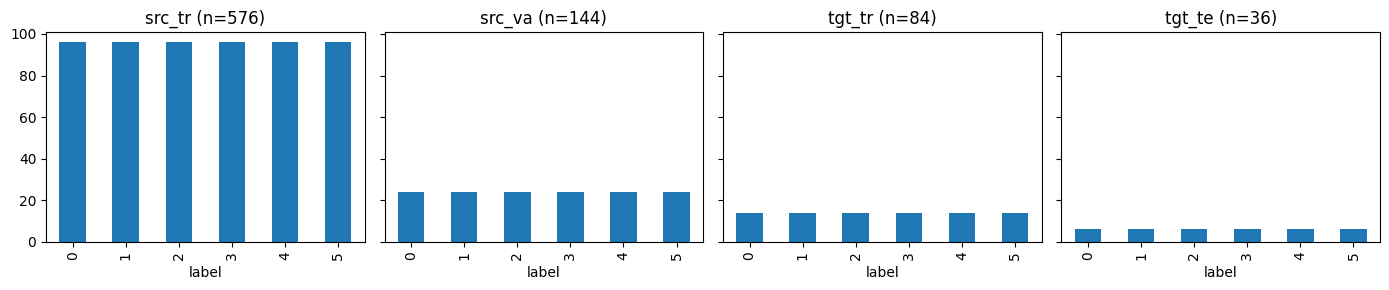

In [3]:
import pandas as pd, matplotlib.pyplot as plt, os, json

# Pastikan folder results ada sebelum menyimpan gambar
os.makedirs('results', exist_ok=True)

cfg = json.load(open('splits/config.json'))
sp = {n: pd.read_csv(f'splits/{n}.csv') for n in ['src_tr', 'src_va', 'tgt_tr', 'tgt_te']}
print("Config Dataset:", cfg)

fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for a_, (n, d) in zip(ax, sp.items()):
    d.label.value_counts().sort_index().plot.bar(ax=a_)
    a_.set_title(f'{n} (n={len(d)})')
plt.tight_layout()
plt.savefig('results/fig_split_distribution.png', dpi=300)
plt.show()

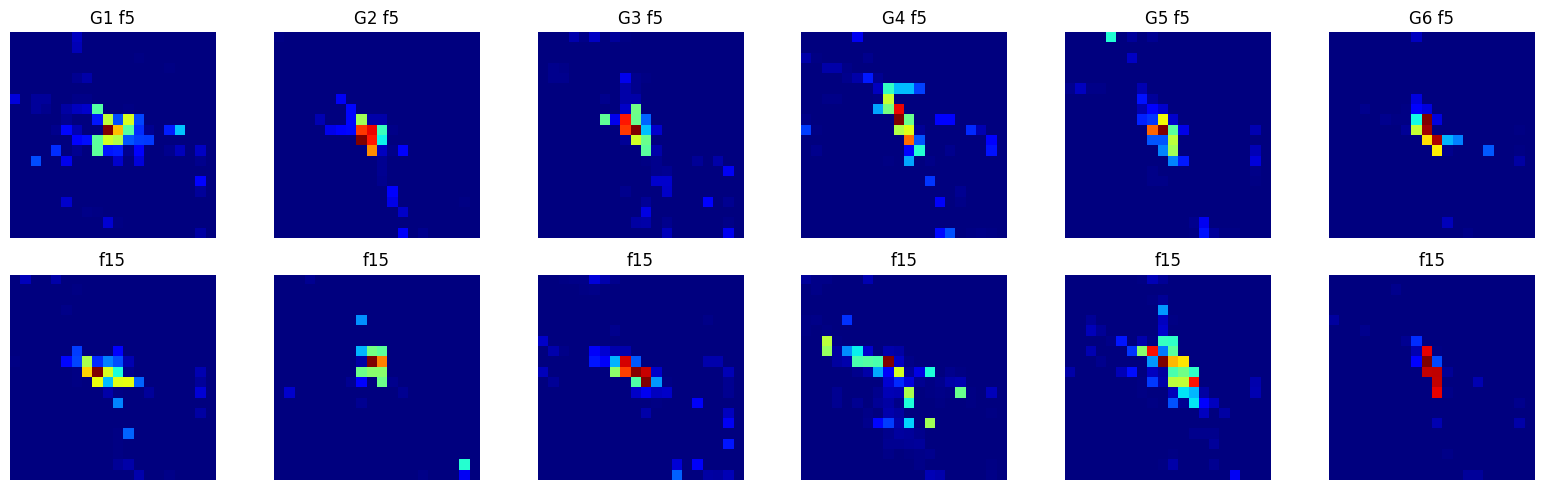

In [4]:
from src.dataset import load_bvp
fig, ax = plt.subplots(2, 6, figsize=(16, 5))
for g in range(len(cfg['GESTURES'])):
    row = sp['src_tr'][sp['src_tr'].label == g].iloc[0]
    x = load_bvp(os.path.join(ROOT, row['rel']))
    ax[0, g].imshow(x[5], cmap='jet')
    ax[0, g].set_title(f"G{cfg['GESTURES'][g]} f5")
    ax[0, g].axis('off')

    ax[1, g].imshow(x[15], cmap='jet')
    ax[1, g].set_title('f15')
    ax[1, g].axis('off')
plt.tight_layout()
plt.savefig('results/fig_bvp_samples.png', dpi=300)
plt.show()

Bentuk raw data: (20, 20, 14)


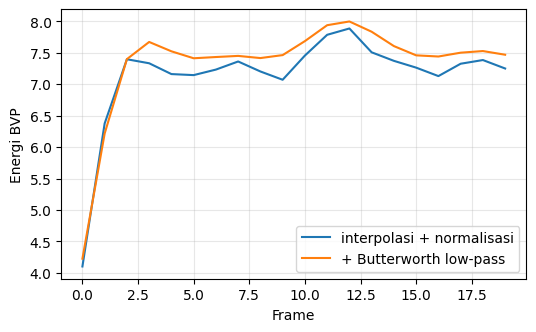

In [5]:
import scipy.io as sio, numpy as np
p = os.path.join(ROOT, sp['src_tr'].iloc[0]['rel'])
raw = sio.loadmat(p)['velocity_spectrum_ro']
print('Bentuk raw data:', raw.shape)

a0, b0 = load_bvp(p, lowpass=False), load_bvp(p, lowpass=True)
plt.figure(figsize=(6, 3.5))
plt.plot(a0.sum(axis=(1, 2)), label='interpolasi + normalisasi')
plt.plot(b0.sum(axis=(1, 2)), label='+ Butterworth low-pass')
plt.xlabel('Frame'); plt.ylabel('Energi BVP'); plt.legend(); plt.grid(alpha=.3)
plt.savefig('results/fig_preprocessing_bvp.png', dpi=300, bbox_inches='tight')
plt.show()

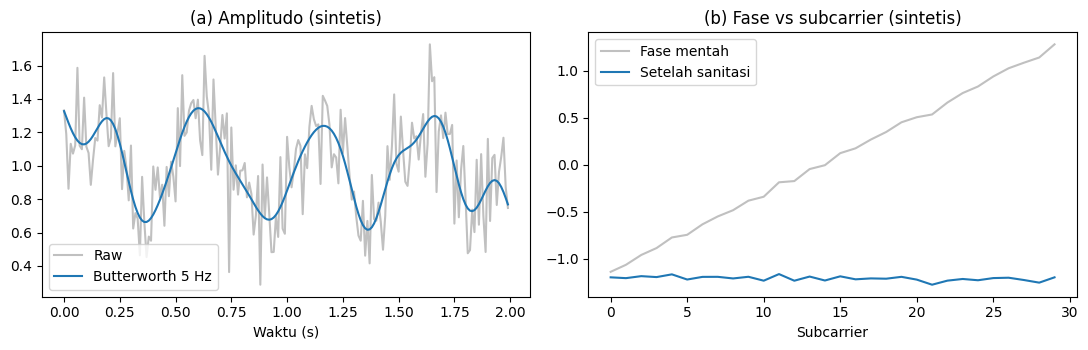

In [6]:
from src.preprocessing import butter_lowpass, sanitize_phase
rng = np.random.default_rng(0)
n_sub, n_pkt, fs = 30, 200, 100
k, t = np.arange(n_sub), np.arange(n_pkt) / fs
true_ph = 0.5 * np.sin(2 * np.pi * 1 * t)[:, None] * np.ones(n_sub)
phase = np.angle(np.exp(1j * (true_ph + rng.uniform(-.3, .3, (n_pkt, 1)) * k
                              + rng.uniform(-np.pi, np.pi, (n_pkt, 1))
                              + 0.02 * rng.standard_normal((n_pkt, n_sub)))))
clean = sanitize_phase(phase)
amp = 1 + 0.3 * np.sin(2 * np.pi * 2 * t) + 0.2 * rng.standard_normal(n_pkt)
amp_f = butter_lowpass(amp, cutoff=5, fs=fs)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t, amp, color='silver', label='Raw'); ax[0].plot(t, amp_f, label='Butterworth 5 Hz')
ax[0].set(title='(a) Amplitudo (sintetis)', xlabel='Waktu (s)'); ax[0].legend()
ax[1].plot(phase[0], color='silver', label='Fase mentah'); ax[1].plot(clean[0], label='Setelah sanitasi')
ax[1].set(title='(b) Fase vs subcarrier (sintetis)', xlabel='Subcarrier'); ax[1].legend()
plt.tight_layout()
plt.savefig('results/fig_csi_illustration.png', dpi=300)
plt.show()

In [7]:
from getpass import getpass
token = getpass('GitHub token: ')
!git remote set-url origin https://{token}@github.com/{USER}/{REPO}.git
!git add -A
!git commit -m "Add splits and preprocessing figures"
!git push origin main

GitHub token: ··········
/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `git remote set-url origin https://import json from src.dataset import make_fold from src.models import BaselineCNNLSTM from src.train import train_baseline, predict from src.utils import set_seed  SEL = pd.read_csv(f"{RESULTS}/selected_samples.csv") for tu in sorted(SEL.user.unique()):     set_seed(SEED)     f = make_fold(SEL, tu, BATCH, seed=SEED)     print(f"\n=== Fold: target = user{tu} | train/val/target = {f['sizes']} ===")     model = BaselineCNNLSTM(num_classes=6)     hist = train_baseline(model, f["train"], f["val"], device, epochs=EPOCHS, lr=LR, weight_decay=WD)     y, p = predict(model, f["target"], device)     print(f"Akurasi target user{tu}: {(y == p).mean()*100:.2f}%")     torch.save(model.state_dict(), f"{RESULTS}/baseline_target_user{tu}.pt")     json.dump(dict(hist=hist, y_true=y.tolist(), y_pred=p.tolist()),               open(f"{RESULTS}/baseline_target_user{

02_baseline_model

In [16]:
import importlib
import src.models
importlib.reload(src.models)
from src.models import CNNLSTM, DANN
import json, torch
from src.dataset import make_datasets
from src.train import run_experiment
from src.utils import plot_curves

cfg = json.load(open('splits/config.json'))
NC = len(cfg['GESTURES'])

ds = make_datasets(ROOT, 'splits', lowpass=False)
print("Jumlah data tiap split:", {k: len(v) for k, v in ds.items()})

model_b, hist_b, rs_b, rt_b = run_experiment(ds, 'baseline', seed=0, num_classes=NC, device=device)
print(f"BASELINE | Source Val Acc: {rs_b['acc']:.3f} | Target Acc: {rt_b['acc']:.3f} | Target F1: {rt_b['f1']:.3f}")

torch.save(model_b.state_dict(), f'{OUT}/baseline.pt')
json.dump(hist_b, open(f'{OUT}/baseline_hist.json', 'w'))
plot_curves(hist_b, 'Baseline CNN-LSTM', f'{OUT}/fig_curve_baseline.png')

Jumlah data tiap split: {'src_tr': 576, 'src_va': 144, 'tgt_tr': 84, 'tgt_te': 36}
BASELINE | Source Val Acc: 0.660 | Target Acc: 0.444 | Target F1: 0.396


In [17]:
from src.utils import plot_cm, plot_tsne

# Membuat nama kelas gestur (misal: G1, G2, dst.)
names = [f'G{g}' for g in cfg['GESTURES']]

# 1. Simpan Confusion Matrix untuk melihat performa per kelas gestur
plot_cm(rt_b['y'], rt_b['pred'], names, 'Baseline CNN-LSTM (CM)', f'{OUT}/fig_cm_baseline.png')

# 2. Simpan visualisasi t-SNE untuk melihat sebaran feature space Source vs Target
plot_tsne(rs_b['z'], rt_b['z'], 'Baseline CNN-LSTM (t-SNE)', f'{OUT}/fig_tsne_baseline.png')

print("Artefak evaluasi tambahan (Confusion Matrix & t-SNE) untuk baseline berhasil disimpan!")

Artefak evaluasi tambahan (Confusion Matrix & t-SNE) untuk baseline berhasil disimpan!


model dilatih hanya di source, dipilih lewat validasi source, dan target tidak pernah dilihat saat training